# EchoNet-Dynamic: Kaggle frame extraction + CNN-BiLSTM training

This notebook adapts `Video_To_Frame_Utility.ipynb` for Kaggle. It keeps the original all-frame PNG extraction workflow, per-batch ZIPs and metadata, then samples 16 evenly spaced frames per video for the MobileNetV3-Small + bidirectional LSTM EF-regression model.

**Before running:** attach the EchoNet-Dynamic dataset under the notebook's **Input** section and enable **Settings → Accelerator → GPU**. The input dataset is read-only; generated files go to `/kaggle/working`.

**Storage warning:** extracting every video frame as PNG can require substantially more storage than the compressed videos. This notebook makes a ZIP per video batch and does not combine them into one giant ZIP. Check free disk space and save a Kaggle notebook version/output after completed batches if you need persistence.

Run the notebook in order. Frame conversion and CNN-LSTM training are separated by a clearly marked section break.


In [2]:
# ============================================================
# CHUNK 1 — INSTALL REQUIRED LIBRARIES (KAGGLE)
# ============================================================
# Kaggle usually has these installed. Uncomment only if a package is missing.
!pip -q install opencv-python-headless pandas numpy tqdm pillow scikit-learn matplotlib


In [3]:
# ============================================================
# CHUNK 2 — IMPORT LIBRARIES (KAGGLE)
# ============================================================

import os
import gc
import cv2
import json
import math
import time
import shutil
import hashlib
import zipfile
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# ============================================================
# CHUNK 3 — CHECK KAGGLE RUNTIME (NO GOOGLE DRIVE MOUNT)
# ============================================================
import torch

print("Kaggle input root: /kaggle/input")
print("Kaggle working root: /kaggle/working")
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected — enable it in Notebook Settings")


Kaggle input root: /kaggle/input
Kaggle working root: /kaggle/working
PyTorch: 2.11.0+cu128
GPU: Tesla T4


In [5]:
# ============================================================
# CHUNK 4 — AUTO-DETECT ECHONET-DYNAMIC DATASET PATH
# ============================================================
# Kaggle attaches datasets under /kaggle/input/<dataset-slug>/.
# This searches for FileList.csv and uses its parent as DATASET_ROOT.

KAGGLE_INPUT_ROOT = "/kaggle/input"
filelist_candidates = []
for root, dirs, files in os.walk(KAGGLE_INPUT_ROOT):
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    for filename in files:
        if filename.lower() == "filelist.csv":
            filelist_candidates.append(os.path.join(root, filename))

if not filelist_candidates:
    raise FileNotFoundError(
        "FileList.csv was not found under /kaggle/input. "
        "Attach the EchoNet-Dynamic dataset in the notebook Input panel."
    )

# Prefer a FileList.csv whose containing tree also contains video files.
VIDEO_EXTENSIONS = {".avi", ".mp4", ".mov", ".mkv", ".mpeg", ".mpg", ".wmv"}
def has_videos_below(folder):
    for root, dirs, files in os.walk(folder):
        if any(Path(name).suffix.lower() in VIDEO_EXTENSIONS for name in files):
            return True
    return False

candidates_with_videos = [p for p in filelist_candidates if has_videos_below(os.path.dirname(p))]
FILELIST_PATH = candidates_with_videos[0] if candidates_with_videos else filelist_candidates[0]
DATASET_ROOT = os.path.abspath(os.path.dirname(FILELIST_PATH))

print("Dataset root:", DATASET_ROOT)
print("FileList.csv:", FILELIST_PATH)
print("Other FileList.csv candidates:", len(filelist_candidates) - 1)


Dataset root: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic
FileList.csv: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv
Other FileList.csv candidates: 0


In [6]:
# ============================================================
# CHUNK 5 — INSPECT DATASET STRUCTURE (KAGGLE)
# ============================================================

print("=" * 70)
print("ECHONET-DYNAMIC DATASET STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(DATASET_ROOT):

    relative = os.path.relpath(root, DATASET_ROOT)

    depth = 0 if relative == "." else relative.count(os.sep) + 1

    if depth > 2:
        continue

    indent = "    " * depth

    folder_name = os.path.basename(root)

    print(f"{indent}{folder_name}/")

    for file in sorted(files)[:15]:

        print(f"{indent}    {file}")

    if len(files) > 15:

        print(
            f"{indent}    ... "
            f"{len(files) - 15} more files"
        )

ECHONET-DYNAMIC DATASET STRUCTURE
EchoNet-Dynamic/
    FileList.csv
    VolumeTracings.csv
    Videos/
        0X100009310A3BD7FC.avi
        0X1002E8FBACD08477.avi
        0X1005D03EED19C65B.avi
        0X10075961BC11C88E.avi
        0X10094BA0A028EAC3.avi
        0X100CF05D141FF143.avi
        0X100E3B8D3280BEC5.avi
        0X100E491B3CD58DE2.avi
        0X100F044876B98F90.avi
        0X101026B90DAE7E95.avi
        0X1012703CDC1436FE.avi
        0X1013E8A4864781B.avi
        0X1018521A3BC5CDBA.avi
        0X101C388397F66EDB.avi
        0X101CFC9C5351DCBE.avi
        ... 10015 more files


In [7]:
# ============================================================
# CHUNK 6 — FIND ALL ECHOCARDIOGRAM VIDEOS
# ============================================================

VIDEO_EXTENSIONS = {
    ".avi",
    ".mp4",
    ".mov",
    ".mkv",
    ".mpeg",
    ".mpg",
    ".wmv"
}

video_files = []

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        extension = Path(filename).suffix.lower()

        if extension in VIDEO_EXTENSIONS:

            video_files.append(
                os.path.join(root, filename)
            )

video_files = sorted(video_files)

print(
    f"Total videos found: {len(video_files):,}"
)

if len(video_files) == 0:

    raise RuntimeError(
        "No video files were found."
    )

print("\nFirst 10 videos:")

for video in video_files[:10]:

    print(video)

Total videos found: 10,030

First 10 videos:
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X100009310A3BD7FC.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X1002E8FBACD08477.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X1005D03EED19C65B.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X10075961BC11C88E.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X10094BA0A028EAC3.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X100CF05D141FF143.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X100E3B8D3280BEC5.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X100E491B3CD58DE2.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos/0X100F044876B98F90.avi
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/E

In [8]:
# ============================================================
# CHUNK 7 — FIND ALL CSV FILES
# ============================================================

csv_files = []

for root, dirs, files in os.walk(DATASET_ROOT):

    for filename in files:

        if filename.lower().endswith(".csv"):

            csv_files.append(
                os.path.join(root, filename)
            )

csv_files = sorted(csv_files)

print(
    f"CSV files found: {len(csv_files)}"
)

for csv_file in csv_files:

    print(
        os.path.relpath(
            csv_file,
            DATASET_ROOT
        )
    )

CSV files found: 2
FileList.csv
VolumeTracings.csv


In [9]:
# ============================================================
# CHUNK 9 — FIND FILELIST.CSV
# ============================================================

filelist_candidates = [

    path

    for path in csv_files

    if os.path.basename(path).lower()
    == "filelist.csv"
]

if not filelist_candidates:

    raise FileNotFoundError(
        "FileList.csv was not found."
    )

FILELIST_PATH = FILELIST_PATH if FILELIST_PATH in filelist_candidates else filelist_candidates[0]

print("Using:")
print(FILELIST_PATH)

filelist_df = pd.read_csv(
    FILELIST_PATH
)

print("\nShape:")
print(filelist_df.shape)

print("\nColumns:")
print(filelist_df.columns.tolist())

display(
    filelist_df.head()
)

Using:
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv

Shape:
(10030, 9)

Columns:
['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


In [10]:
# ============================================================
# CHUNK 10 — INSPECT ORIGINAL LABELS
# ============================================================

print("=" * 70)
print("ECHONET LABEL / TARGET INFORMATION")
print("=" * 70)

for column in filelist_df.columns:

    print(
        f"{column:25s} "
        f"| dtype={filelist_df[column].dtype} "
        f"| missing={filelist_df[column].isna().sum()}"
    )

ECHONET LABEL / TARGET INFORMATION
FileName                  | dtype=object | missing=0
EF                        | dtype=float64 | missing=0
ESV                       | dtype=float64 | missing=0
EDV                       | dtype=float64 | missing=0
FrameHeight               | dtype=int64 | missing=0
FrameWidth                | dtype=int64 | missing=0
FPS                       | dtype=int64 | missing=0
NumberOfFrames            | dtype=int64 | missing=0
Split                     | dtype=object | missing=0


In [11]:
# ============================================================
# CHUNK 11 — IDENTIFY VIDEO NAME COLUMN
# ============================================================

possible_video_columns = [
    "FileName",
    "Filename",
    "file_name",
    "filename",
    "Video",
    "video",
    "VideoName",
    "video_name"
]

VIDEO_COLUMN = None

for column in possible_video_columns:

    if column in filelist_df.columns:

        VIDEO_COLUMN = column
        break

if VIDEO_COLUMN is None:

    raise ValueError(
        "Could not automatically identify "
        "the video filename column.\n\n"
        f"Available columns:\n"
        f"{filelist_df.columns.tolist()}"
    )

print(
    "Video filename column:",
    VIDEO_COLUMN
)

Video filename column: FileName


In [12]:
# ============================================================
# CHUNK 12 — BUILD VIDEO LOOKUP TABLE
# ============================================================

video_lookup = {}

for path in video_files:

    filename = os.path.basename(path)

    stem = os.path.splitext(
        filename
    )[0]

    video_lookup[filename] = path
    video_lookup[stem] = path

print(
    "Video lookup entries:",
    len(video_lookup)
)

Video lookup entries: 20060


In [13]:
# ============================================================
# CHUNK 13 — MATCH METADATA TO ACTUAL VIDEOS
# ============================================================

matched_paths = []
unmatched_rows = []

for index, row in filelist_df.iterrows():

    value = str(
        row[VIDEO_COLUMN]
    ).strip()

    basename = os.path.basename(value)

    stem = os.path.splitext(
        basename
    )[0]

    path = None

    if basename in video_lookup:

        path = video_lookup[basename]

    elif stem in video_lookup:

        path = video_lookup[stem]

    if path is None:

        unmatched_rows.append(index)

        matched_paths.append(None)

    else:

        matched_paths.append(path)

filelist_df = filelist_df.copy()

filelist_df["source_video_path"] = matched_paths

matched_count = (
    filelist_df["source_video_path"]
    .notna()
    .sum()
)

print(
    f"Matched videos: {matched_count:,}"
)

print(
    f"Unmatched metadata rows: "
    f"{len(unmatched_rows):,}"
)

if len(unmatched_rows) > 0:

    print(
        "\nWARNING: Some metadata rows "
        "could not be matched."
    )

Matched videos: 10,030
Unmatched metadata rows: 0


In [14]:
# ============================================================
# CHUNK 14 — DATASET VALIDATION
# ============================================================

if matched_count == 0:

    raise RuntimeError(
        "No metadata rows matched videos."
    )

print("=" * 70)
print("DATASET VALIDATION")
print("=" * 70)

print(
    "Metadata rows:",
    len(filelist_df)
)

print(
    "Videos found:",
    len(video_files)
)

print(
    "Matched rows:",
    matched_count
)

print(
    "Unmatched rows:",
    len(unmatched_rows)
)

if "Split" in filelist_df.columns:

    print(
        "\nOriginal dataset split:"
    )

    print(
        filelist_df["Split"]
        .value_counts()
    )

DATASET VALIDATION
Metadata rows: 10030
Videos found: 10030
Matched rows: 10030
Unmatched rows: 0

Original dataset split:
Split
TRAIN    7465
VAL      1288
TEST     1277
Name: count, dtype: int64


In [15]:
# ============================================================
# CHUNK 15 — CREATE KAGGLE WORKING OUTPUT DIRECTORIES
# ============================================================
WORK_ROOT = "/kaggle/working/EchoNet_Frame_Utility"
FRAME_DIR = os.path.join(WORK_ROOT, "frames")
PARTS_DIR = os.path.join("/kaggle/working", "EchoNet_Download_Parts")
LOG_DIR = os.path.join(WORK_ROOT, "logs")

os.makedirs(FRAME_DIR, exist_ok=True)
os.makedirs(PARTS_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

print("Work directory:", WORK_ROOT)
print("Batch ZIP / metadata directory:", PARTS_DIR)


Work directory: /kaggle/working/EchoNet_Frame_Utility
Batch ZIP / metadata directory: /kaggle/working/EchoNet_Download_Parts


In [16]:
# ============================================================
# CHUNK 16 — CHECK KAGGLE WORKING STORAGE
# ============================================================

def get_free_space_gb(
    path="/kaggle/working"
):

    total, used, free = (
        shutil.disk_usage(path)
    )

    return (
        total / (1024**3),
        used / (1024**3),
        free / (1024**3)
    )

total_gb, used_gb, free_gb = (
    get_free_space_gb()
)

print(
    f"Total storage: {total_gb:.2f} GB"
)

print(
    f"Used storage : {used_gb:.2f} GB"
)

print(
    f"Free storage : {free_gb:.2f} GB"
)

Total storage: 19.52 GB
Used storage : 0.00 GB
Free storage : 19.50 GB


In [18]:
# ============================================================
# CHUNK 17 — COMPLETE FRAME EXTRACTION UTILITY (UNCHANGED EXTRACTION LOGIC)
# ============================================================

def extract_video_to_frames(
    video_path,
    output_root,
    metadata_row
):

    video_filename = os.path.basename(
        video_path
    )

    video_id = os.path.splitext(
        video_filename
    )[0]

    video_output_dir = os.path.join(
        output_root,
        video_id
    )

    os.makedirs(
        video_output_dir,
        exist_ok=True
    )

    cap = cv2.VideoCapture(
        video_path
    )

    if not cap.isOpened():

        return {
            "success": False,
            "video_id": video_id,
            "frames": 0,
            "error": "Unable to open video",
            "records": []
        }

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    width = int(
        cap.get(
            cv2.CAP_PROP_FRAME_WIDTH
        )
    )

    height = int(
        cap.get(
            cv2.CAP_PROP_FRAME_HEIGHT
        )
    )

    frame_count = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if fps <= 0:

        fps = None

    records = []

    frame_index = 0

    while True:

        success, frame = cap.read()

        if not success:
            break

        frame_filename = (
            f"{video_id}_"
            f"frame_{frame_index:06d}.png"
        )

        frame_path = os.path.join(
            video_output_dir,
            frame_filename
        )

        # ----------------------------------------------------
        # Save decoded frame as PNG.
        # No resize.
        # No crop.
        # No normalization.
        # ----------------------------------------------------

        saved = cv2.imwrite(
            frame_path,
            frame,
            [
                cv2.IMWRITE_PNG_COMPRESSION,
                3
            ]
        )

        if not saved:

            cap.release()

            return {
                "success": False,
                "video_id": video_id,
                "frames": frame_index,
                "error": (
                    "Failed to save frame"
                ),
                "records": records
            }

        timestamp = (
            frame_index / fps
            if fps is not None
            else None
        )

        record = {

            "video_id":
                video_id,

            "source_video":
                video_filename,

            "source_video_path":
                video_path,

            "frame_index":
                frame_index,

            "timestamp_seconds":
                timestamp,

            "fps":
                fps,

            "width":
                width,

            "height":
                height,

            "frame_count_reported":
                frame_count,

            "frame_filename":
                frame_filename,

            "relative_frame_path":
                os.path.join(
                    video_id,
                    frame_filename
                )
        }

        # ----------------------------------------------------
        # Preserve EVERY original metadata field
        # ----------------------------------------------------

        for column in metadata_row.index:

            key = str(column)

            if key not in record:

                value = metadata_row[column]

                if pd.isna(value):

                    value = None

                record[
                    f"label_{key}"
                ] = value

        records.append(
            record
        )

        frame_index += 1

    cap.release()

    return {

        "success": True,

        "video_id":
            video_id,

        "frames":
            frame_index,

        "error":
            "",

        "records":
            records,

        "fps":
            fps,

        "width":
            width,

        "height":
            height,

        "reported_frame_count":
            frame_count
    }

In [19]:
# ============================================================
# CHUNK 18 — TEST EXTRACTION ON ONE VIDEO
# ============================================================

# Define the test video using the first available video path
if 'video_files' in globals() and len(video_files) > 0:
    test_video = video_files[0]
else:
    raise RuntimeError("No video files available to test with.")

# Remove previous test frames
TEST_DIR = "/kaggle/working/EchoNet_Test"

if os.path.exists(TEST_DIR):
    shutil.rmtree(TEST_DIR)

os.makedirs(TEST_DIR, exist_ok=True)

test_row = filelist_df[
    filelist_df["source_video_path"]
    == test_video
]

if len(test_row) == 0:
    raise RuntimeError(
        "Could not find metadata for test video."
    )

test_row = test_row.iloc[0]

test_result = extract_video_to_frames(
    test_video,
    TEST_DIR,
    test_row
)

print(
    "Success:",
    test_result["success"]
)

print(
    "Frames extracted:",
    test_result["frames"]
)

print(
    "FPS:",
    test_result.get("fps")
)

print(
    "Resolution:",
    test_result.get("width"),
    "x",
    test_result.get("height")
)

Success: True
Frames extracted: 174
FPS: 50.0
Resolution: 112 x 112


PNG frames found: 174

First frame:
/kaggle/working/EchoNet_Test/0X100009310A3BD7FC/0X100009310A3BD7FC_frame_000000.png

PNG dimensions: (112, 112)
PNG mode: RGB


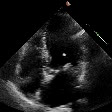

In [20]:
# ============================================================
# CHUNK 19 — VERIFY TEST FRAMES
# ============================================================

test_pngs = []

for root, dirs, files in os.walk(
    TEST_DIR
):

    for file in files:

        if file.lower().endswith(
            ".png"
        ):

            test_pngs.append(
                os.path.join(
                    root,
                    file
                )
            )

test_pngs = sorted(
    test_pngs
)

print(
    "PNG frames found:",
    len(test_pngs)
)

if len(test_pngs) > 0:

    print(
        "\nFirst frame:"
    )

    print(
        test_pngs[0]
    )

    image = Image.open(
        test_pngs[0]
    )

    print(
        "\nPNG dimensions:",
        image.size
    )

    print(
        "PNG mode:",
        image.mode
    )

    display(
        image
    )

In [21]:
# ============================================================
# CHUNK 20 — VERIFY FRAME ORDER
# ============================================================

test_video_id = os.path.splitext(
    os.path.basename(test_video)
)[0]

test_video_dir = os.path.join(
    TEST_DIR,
    test_video_id
)

test_frames = sorted(
    [
        f
        for f in os.listdir(
            test_video_dir
        )
        if f.endswith(".png")
    ]
)

print(
    "First 10 frames:"
)

for frame in test_frames[:10]:

    print(frame)

print(
    "\nLast 5 frames:"
)

for frame in test_frames[-5:]:

    print(frame)

First 10 frames:
0X100009310A3BD7FC_frame_000000.png
0X100009310A3BD7FC_frame_000001.png
0X100009310A3BD7FC_frame_000002.png
0X100009310A3BD7FC_frame_000003.png
0X100009310A3BD7FC_frame_000004.png
0X100009310A3BD7FC_frame_000005.png
0X100009310A3BD7FC_frame_000006.png
0X100009310A3BD7FC_frame_000007.png
0X100009310A3BD7FC_frame_000008.png
0X100009310A3BD7FC_frame_000009.png

Last 5 frames:
0X100009310A3BD7FC_frame_000169.png
0X100009310A3BD7FC_frame_000170.png
0X100009310A3BD7FC_frame_000171.png
0X100009310A3BD7FC_frame_000172.png
0X100009310A3BD7FC_frame_000173.png


In [22]:
# ============================================================
# CHUNK 21 — REMOVE TEST DATA
# ============================================================

if os.path.exists(TEST_DIR):

    shutil.rmtree(
        TEST_DIR
    )

print(
    "Test data removed."
)

print(
    "Full processing can now begin."
)

Test data removed.
Full processing can now begin.


In [23]:
# ============================================================
# CHUNK 22 — BATCH CONFIGURATION
# ============================================================

VIDEOS_PER_BATCH = 20

# Safety margin for Kaggle working storage.
MIN_FREE_SPACE_GB = 5.0

print(
    "Videos per batch:",
    VIDEOS_PER_BATCH
)

print(
    "Minimum desired free storage:",
    MIN_FREE_SPACE_GB,
    "GB"
)

Videos per batch: 20
Minimum desired free storage: 5.0 GB


In [24]:
# ============================================================
# CHUNK 23 — FULL DATASET PROCESSING UTILITY (BATCH ZIP OUTPUT)
# ============================================================

def process_batch(
    batch_number,
    batch_df
):

    print("\n")
    print("=" * 80)
    print(
        f"PROCESSING BATCH {batch_number}"
    )
    print(
        f"Videos: {len(batch_df)}"
    )
    print("=" * 80)

    # --------------------------------------------------------
    # Clean temporary frame directory
    # --------------------------------------------------------

    if os.path.exists(
        FRAME_DIR
    ):

        shutil.rmtree(
            FRAME_DIR
        )

    os.makedirs(
        FRAME_DIR,
        exist_ok=True
    )

    batch_records = []

    errors = []

    # --------------------------------------------------------
    # Process each video
    # --------------------------------------------------------

    for _, row in tqdm(
        batch_df.iterrows(),
        total=len(batch_df),
        desc=f"Batch {batch_number}"
    ):

        video_path = row[
            "source_video_path"
        ]

        result = extract_video_to_frames(
            video_path,
            FRAME_DIR,
            row
        )

        if result["success"]:

            batch_records.extend(
                result["records"]
            )

        else:

            errors.append({

                "video":
                    video_path,

                "video_id":
                    result["video_id"],

                "error":
                    result["error"]
            })

    # --------------------------------------------------------
    # Save frame metadata
    # --------------------------------------------------------

    batch_metadata_df = pd.DataFrame(
        batch_records
    )

    metadata_filename = (
        f"EchoNet_Frame_Metadata_"
        f"Batch_{batch_number:04d}.csv"
    )

    metadata_path = os.path.join(
        PARTS_DIR,
        metadata_filename
    )

    batch_metadata_df.to_csv(
        metadata_path,
        index=False
    )

    # --------------------------------------------------------
    # Save errors
    # --------------------------------------------------------

    error_filename = (
        f"EchoNet_Errors_"
        f"Batch_{batch_number:04d}.csv"
    )

    error_path = os.path.join(
        PARTS_DIR,
        error_filename
    )

    pd.DataFrame(
        errors
    ).to_csv(
        error_path,
        index=False
    )

    # --------------------------------------------------------
    # Create ZIP
    # --------------------------------------------------------

    archive_base = os.path.join(
        PARTS_DIR,
        f"EchoNet_Frame_Dataset_"
        f"Part_{batch_number:04d}"
    )

    print(
        "\nCreating ZIP archive..."
    )

    shutil.make_archive(
        archive_base,
        "zip",
        FRAME_DIR
    )

    archive_path = (
        archive_base + ".zip"
    )

    archive_size_gb = (
        os.path.getsize(
            archive_path
        )
        / (1024 ** 3)
    )

    print(
        "\nArchive created:"
    )

    print(
        archive_path
    )

    print(
        f"Archive size: "
        f"{archive_size_gb:.2f} GB"
    )

    # --------------------------------------------------------
    # Delete temporary PNG files
    # --------------------------------------------------------

    shutil.rmtree(
        FRAME_DIR
    )

    gc.collect()

    return {

        "batch_number":
            batch_number,

        "videos":
            len(batch_df),

        "frames":
            len(batch_records),

        "errors":
            len(errors),

        "archive":
            archive_path,

        "metadata":
            metadata_path,

        "archive_size_gb":
            archive_size_gb
    }

In [25]:
# ============================================================
# CHUNK 24 — RUN COMPLETE ECHONET FRAME CONVERSION
# ============================================================

# Only rows with an actual video
# are processed.

processing_df = filelist_df[
    filelist_df["source_video_path"]
    .notna()
].copy()

processing_df = processing_df.reset_index(
    drop=True
)

total_videos = len(
    processing_df
)

print(
    f"Videos to process: "
    f"{total_videos:,}"
)

num_batches = math.ceil(
    total_videos /
    VIDEOS_PER_BATCH
)

print(
    f"Number of batches: "
    f"{num_batches}"
)

batch_results = []

for batch_number in range(
    1,
    num_batches + 1
):

    # --------------------------------------------------------
    # Check whether this batch already exists
    # --------------------------------------------------------

    archive_path = os.path.join(
        PARTS_DIR,
        f"EchoNet_Frame_Dataset_"
        f"Part_{batch_number:04d}.zip"
    )

    if os.path.exists(
        archive_path
    ):

        print(
            f"\nBatch {batch_number} "
            f"already exists."
        )

        print(
            "Skipping it."
        )

        continue

    # --------------------------------------------------------
    # Select batch
    # --------------------------------------------------------

    start = (
        (batch_number - 1)
        * VIDEOS_PER_BATCH
    )

    end = min(
        start + VIDEOS_PER_BATCH,
        total_videos
    )

    batch_df = processing_df.iloc[
        start:end
    ]

    # --------------------------------------------------------
    # Process
    # --------------------------------------------------------

    result = process_batch(
        batch_number,
        batch_df
    )

    batch_results.append(
        result
    )

    # --------------------------------------------------------
    # Check storage
    # --------------------------------------------------------

    total_gb, used_gb, free_gb = (
        get_free_space_gb()
    )

    print(
        f"\nRemaining Kaggle working storage: "
        f"{free_gb:.2f} GB"
    )

    if free_gb < MIN_FREE_SPACE_GB:

        print(
            "\nSTOPPING SAFELY."
        )

        print(
            "Colab storage is getting low."
        )

        break

print(
    "\nDataset processing loop finished."
)

Videos to process: 10,030
Number of batches: 502


PROCESSING BATCH 1
Videos: 20


Batch 1:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0001.zip
Archive size: 0.04 GB

Remaining Kaggle working storage: 19.46 GB


PROCESSING BATCH 2
Videos: 20


Batch 2:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0002.zip
Archive size: 0.04 GB

Remaining Kaggle working storage: 19.42 GB


PROCESSING BATCH 3
Videos: 20


Batch 3:   0%|          | 0/20 [00:00<?, ?it/s]

... (703 outputs left out)

Batch 355:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0355.zip
Archive size: 0.04 GB

Remaining Kaggle working storage: 5.04 GB


PROCESSING BATCH 356
Videos: 20


Batch 356:   0%|          | 0/20 [00:00<?, ?it/s]


Creating ZIP archive...

Archive created:
/kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Dataset_Part_0356.zip
Archive size: 0.04 GB

Remaining Kaggle working storage: 5.00 GB

STOPPING SAFELY.
Colab storage is getting low.

Dataset processing loop finished.


In [26]:
# ============================================================
# CHUNK 25 — BUILD MASTER FRAME METADATA
# ============================================================

metadata_files = sorted([

    os.path.join(
        PARTS_DIR,
        filename
    )

    for filename in os.listdir(
        PARTS_DIR
    )

    if (
        filename.startswith(
            "EchoNet_Frame_Metadata_Batch_"
        )
        and filename.endswith(".csv")
    )

])

print(
    "Metadata batch files:",
    len(metadata_files)
)

master_metadata_path = os.path.join(
    PARTS_DIR,
    "EchoNet_Frame_Metadata_MASTER.csv"
)

if metadata_files:

    frames = []

    for file in tqdm(
        metadata_files,
        desc="Combining metadata"
    ):

        frames.append(
            pd.read_csv(file)
        )

    master_metadata = pd.concat(
        frames,
        ignore_index=True
    )

    master_metadata.to_csv(
        master_metadata_path,
        index=False
    )

    print(
        "\nMaster metadata saved:"
    )

    print(
        master_metadata_path
    )

    print(
        "\nTotal frame records:",
        len(master_metadata)
    )

else:

    print(
        "No metadata files found."
    )

Metadata batch files: 356


Combining metadata:   0%|          | 0/356 [00:00<?, ?it/s]


Master metadata saved:
/kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Metadata_MASTER.csv

Total frame records: 1258176


In [28]:
# ============================================================
# CHUNK 26 — CREATE VIDEO-LEVEL MANIFEST
# ============================================================

video_manifest_columns = [
    column
    for column in filelist_df.columns
]

video_manifest = filelist_df[
    video_manifest_columns
].copy()

VIDEO_MANIFEST_PATH = os.path.join(
    PARTS_DIR,
    "EchoNet_Video_Level_Manifest.csv"
)

video_manifest.to_csv(
    VIDEO_MANIFEST_PATH,
    index=False
)

print(
    "Video-level manifest saved:"
)

print(
    VIDEO_MANIFEST_PATH
)

print(
    "\nThis file must be used to keep "
    "train/validation/test separation "
    "at the VIDEO level."
)

Video-level manifest saved:
/kaggle/working/EchoNet_Download_Parts/EchoNet_Video_Level_Manifest.csv

This file must be used to keep train/validation/test separation at the VIDEO level.


In [29]:
# ============================================================
# CHUNK 27 — CREATE DATASET README
# ============================================================

README_PATH = os.path.join(
    PARTS_DIR,
    "README_EchoNet_Frame_Dataset.txt"
)

readme = f"""
ECHONET-DYNAMIC FRAME-SEQUENCE DATASET
======================================

Source:
EchoNet-Dynamic

Purpose:
Derived image/frame dataset for conventional CNN
and frame-sequence experiments.

SOURCE VIDEOS
-------------
Original EchoNet-Dynamic videos are NOT modified.

FRAME EXTRACTION
----------------
Every successfully decoded video frame was extracted.

Frame skipping:
None.

Resizing:
None.

Cropping:
None.

Additional lossy compression:
None.

Output frame format:
PNG.

Frame ordering:
Preserved using frame_index.

Temporal metadata:
Preserved using:
- frame_index
- timestamp_seconds
- fps
- video_id

Spatial metadata:
Preserved using:
- width
- height

Clinical metadata:
Original FileList.csv fields are preserved
with each frame record using the label_ prefix.

Video-level metadata:
EchoNet_Video_Level_Manifest.csv

Frame-level metadata:
EchoNet_Frame_Metadata_MASTER.csv

IMPORTANT EXPERIMENTAL RULE
---------------------------
Do NOT randomly split individual frames into
train/validation/test.

The split must remain at VIDEO level.

Reason:
Frames from the same video are highly correlated.
Splitting frames randomly can cause data leakage.

ORIGINAL DATA
-------------
The original EchoNet-Dynamic dataset should be retained
as the source/reference dataset.

OUTPUT
------
The frame dataset is distributed as multiple ZIP parts
because the complete extracted dataset may be much larger
than available Colab or Google Drive storage.

Generated videos:
{len(video_files)}

Generated frame records:
{
    len(master_metadata)
    if 'master_metadata' in globals()
    else 'Not yet available'
}

Research use:
This derived dataset is for non-clinical research.
Follow the original EchoNet-Dynamic research-use agreement.
"""

with open(
    README_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        readme
    )

print(
    "README created:"
)

print(
    README_PATH
)

README created:
/kaggle/working/EchoNet_Download_Parts/README_EchoNet_Frame_Dataset.txt


In [30]:
# ============================================================
# CHUNK 28 — FINAL DATASET VERIFICATION
# ============================================================

print("=" * 80)
print("FINAL ECHONET FRAME DATASET REPORT")
print("=" * 80)

print(
    "\nSource videos:",
    len(video_files)
)

if "master_metadata" in globals():

    print(
        "Frame records:",
        len(master_metadata)
    )

print(
    "\nOutput files:"
)

output_files = sorted(
    os.listdir(
        PARTS_DIR
    )
)

for filename in output_files:

    path = os.path.join(
        PARTS_DIR,
        filename
    )

    if os.path.isfile(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"{filename:60s}"
            f"{size_mb:12,.2f} MB"
        )

print(
    "\n" + "=" * 80
)

print(
    "FRAME-SEQUENCE DATASET CREATION COMPLETE"
)

print(
    "=" * 80
)

FINAL ECHONET FRAME DATASET REPORT

Source videos: 10030
Frame records: 1258176

Output files:
EchoNet_Errors_Batch_0001.csv                                       0.00 MB
EchoNet_Errors_Batch_0002.csv                                       0.00 MB
EchoNet_Errors_Batch_0003.csv                                       0.00 MB
EchoNet_Errors_Batch_0004.csv                                       0.00 MB
EchoNet_Errors_Batch_0005.csv                                       0.00 MB
EchoNet_Errors_Batch_0006.csv                                       0.00 MB
EchoNet_Errors_Batch_0007.csv                                       0.00 MB
EchoNet_Errors_Batch_0008.csv                                       0.00 MB
EchoNet_Errors_Batch_0009.csv                                       0.00 MB
EchoNet_Errors_Batch_0010.csv                                       0.00 MB
EchoNet_Errors_Batch_0011.csv                                       0.00 MB
EchoNet_Errors_Batch_0012.csv                                       0

In [31]:
# ============================================================
# CHUNK 29 — FRAME-CONVERSION CHECKPOINT (NO GIANT ZIP MERGE)
# ============================================================
# The original Colab notebook combined every batch ZIP into one huge ZIP.
# On Kaggle this can require another full copy of the derived dataset, so
# this Kaggle adaptation intentionally keeps the per-batch ZIPs separate.

batch_zips = sorted(
    os.path.join(PARTS_DIR, name)
    for name in os.listdir(PARTS_DIR)
    if name.startswith("EchoNet_Frame_Dataset_Part_") and name.endswith(".zip")
)
print("Batch ZIP files:", len(batch_zips))
print("Frame metadata master:", os.path.join(PARTS_DIR, "EchoNet_Frame_Metadata_MASTER.csv"))
print("Video manifest:", os.path.join(PARTS_DIR, "EchoNet_Video_Level_Manifest.csv"))
print("\nIf conversion is complete, save a Kaggle notebook version now if you need the generated files to persist.")


Batch ZIP files: 356
Frame metadata master: /kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Metadata_MASTER.csv
Video manifest: /kaggle/working/EchoNet_Download_Parts/EchoNet_Video_Level_Manifest.csv

If conversion is complete, save a Kaggle notebook version now if you need the generated files to persist.


# ============================================================
# SECTION BREAK — CNN + BiLSTM TRAINING AND TESTING
# ============================================================

**Run the cells below only after frame conversion, master metadata creation, and the batch ZIPs are complete.** This stage samples 16 evenly spaced frames per video, uses the original video-level TRAIN/VAL/TEST split, trains MobileNetV3-Small + BiLSTM for EF regression, and writes metrics/predictions/plots to `/kaggle/working/EchoNet_CNN_LSTM_Results`.

The source notebook's CNN-LSTM architecture and evaluation logic are retained; paths and ZIP handling are adapted for Kaggle.


In [32]:
# CELL 1 — SET PATHS, CHECK BATCH ARCHIVES, AND GPU (KAGGLE)
import os, glob, random
import numpy as np
import pandas as pd
import torch
import torchvision
from pathlib import Path

ZIP_PATHS = sorted(glob.glob(os.path.join(PARTS_DIR, "EchoNet_Frame_Dataset_Part_*.zip")))
MASTER_META_PATH = os.path.join(PARTS_DIR, "EchoNet_Frame_Metadata_MASTER.csv")
FILELIST_PATH = FILELIST_PATH
CACHE_DIR = "/kaggle/working/echonet_cnn_lstm_sequences"
OUTPUT_DIR = "/kaggle/working/EchoNet_CNN_LSTM_Results"
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. Enable GPU in Kaggle notebook settings.")

for path in [MASTER_META_PATH, FILELIST_PATH]:
    print(f"{'FOUND' if os.path.exists(path) else 'MISSING'}: {path}")
print("Batch ZIP files found:", len(ZIP_PATHS))
assert os.path.exists(MASTER_META_PATH), "Master frame metadata not found. Complete the frame-conversion section first."
assert os.path.exists(FILELIST_PATH), "Original FileList.csv not found."
assert len(ZIP_PATHS) > 0, "No frame batch ZIPs found. Complete the frame-conversion section first."
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Cache directory:", CACHE_DIR)
print("Results directory:", OUTPUT_DIR)


GPU: Tesla T4
FOUND: /kaggle/working/EchoNet_Download_Parts/EchoNet_Frame_Metadata_MASTER.csv
FOUND: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv
Batch ZIP files found: 356
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Cache directory: /kaggle/working/echonet_cnn_lstm_sequences
Results directory: /kaggle/working/EchoNet_CNN_LSTM_Results


In [33]:
import os
import re
import numpy as np
import pandas as pd

N_FRAMES = 16

def normalize_video_id(value):
    value = os.path.basename(str(value).strip())
    value = re.sub(
        r"\.(avi|mp4|mov|mkv)$",
        "",
        value,
        flags=re.IGNORECASE
    )
    return value

# Read original EchoNet-Dynamic labels
file_df = pd.read_csv(FILELIST_PATH)

required_cols = [
    "FileName", "EF", "NumberOfFrames", "Split"
]

missing = [c for c in required_cols if c not in file_df.columns]
assert not missing, f"Missing FileList columns: {missing}"

file_df["video_id"] = file_df["FileName"].apply(
    normalize_video_id
)
file_df["EF"] = pd.to_numeric(
    file_df["EF"], errors="coerce"
)
file_df["NumberOfFrames"] = pd.to_numeric(
    file_df["NumberOfFrames"], errors="coerce"
)
file_df["Split"] = (
    file_df["Split"].astype(str).str.upper().str.strip()
)

# Normalize common split naming variations
file_df["Split"] = file_df["Split"].replace({
    "VALIDATION": "VAL",
    "VALID": "VAL"
})

labels = file_df[
    ["video_id", "EF", "NumberOfFrames", "Split"]
].dropna(subset=["EF", "NumberOfFrames"]).copy()

labels["NumberOfFrames"] = labels["NumberOfFrames"].astype(int)
labels = labels[
    (labels["NumberOfFrames"] > 0) &
    (labels["EF"].between(0, 100)) &
    (labels["Split"].isin(["TRAIN", "VAL", "TEST"]))
].drop_duplicates("video_id")

print("Videos with valid labels:", len(labels))
print("\nOfficial video splits:")
print(labels["Split"].value_counts())

assert {"TRAIN", "VAL", "TEST"}.issubset(
    set(labels["Split"])
), "TRAIN, VAL and TEST splits must all be present."

# Build target frame indices and allow +/- 1 as a safeguard
# against zero-based versus one-based frame indexing.
target_rows = []

for row in labels.itertuples(index=False):
    n = int(row.NumberOfFrames)

    target_indices = np.linspace(
        0, n - 1, N_FRAMES
    ).round().astype(int)

    for seq_pos, desired_idx in enumerate(target_indices):
        candidates = sorted(set([
            max(0, int(desired_idx) - 1),
            int(desired_idx),
            int(desired_idx) + 1
        ]))

        for candidate_idx in candidates:
            target_rows.append({
                "video_id": row.video_id,
                "seq_pos": seq_pos,
                "desired_frame_index": int(desired_idx),
                "candidate_frame_index": candidate_idx
            })

targets = pd.DataFrame(target_rows)

print("Target frame candidates:", len(targets))

# Read only the columns needed from the large master CSV
meta_columns = [
    "video_id",
    "frame_index",
    "relative_frame_path"
]

selected_chunks = []
metadata_rows_read = 0

for chunk in pd.read_csv(
    MASTER_META_PATH,
    usecols=meta_columns,
    chunksize=100_000
):
    metadata_rows_read += len(chunk)

    chunk["video_id"] = chunk["video_id"].apply(
        normalize_video_id
    )
    chunk["frame_index"] = pd.to_numeric(
        chunk["frame_index"], errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["video_id", "frame_index", "relative_frame_path"]
    )
    chunk["frame_index"] = chunk["frame_index"].astype(int)

    # Match only the frame indices needed for our sequences
    matched = chunk.merge(
        targets,
        left_on=["video_id", "frame_index"],
        right_on=["video_id", "candidate_frame_index"],
        how="inner"
    )

    if not matched.empty:
        matched["distance"] = (
            matched["frame_index"] -
            matched["desired_frame_index"]
        ).abs()

        selected_chunks.append(
            matched[[
                "video_id",
                "seq_pos",
                "desired_frame_index",
                "frame_index",
                "relative_frame_path",
                "distance"
            ]]
        )

    if metadata_rows_read % 500_000 == 0:
        print("Metadata rows scanned:", metadata_rows_read)

assert selected_chunks, (
    "No matching frames found. Check the metadata column names, "
    "video IDs and frame-index convention."
)

found = pd.concat(selected_chunks, ignore_index=True)

# For each desired sequence position, select the closest real frame.
found = found.sort_values(
    ["video_id", "seq_pos", "distance", "frame_index"]
)
found = found.drop_duplicates(
    ["video_id", "seq_pos"], keep="first"
)

# Keep only videos with all 16 sequence positions
coverage = found.groupby("video_id")["seq_pos"].nunique()
complete_video_ids = coverage[coverage == N_FRAMES].index

found = found[
    found["video_id"].isin(complete_video_ids)
].copy()

# Attach ground-truth EF and official split
found = found.merge(
    labels[["video_id", "EF", "Split"]],
    on="video_id",
    how="inner"
)

SELECTED_MAP_PATH = os.path.join(
    OUTPUT_DIR, "selected_frame_map.csv"
)

found.to_csv(SELECTED_MAP_PATH, index=False)

print("\nSelected frame records:", len(found))
print("Complete videos:", found["video_id"].nunique())
print("\nVideos by split:")
print(
    found[["video_id", "Split"]]
    .drop_duplicates()["Split"]
    .value_counts()
)
print("\nSaved frame map:", SELECTED_MAP_PATH)

assert found["video_id"].nunique() > 0

Videos with valid labels: 10030

Official video splits:
Split
TRAIN    7465
VAL      1288
TEST     1277
Name: count, dtype: int64
Target frame candidates: 471410
Metadata rows scanned: 500000
Metadata rows scanned: 1000000

Selected frame records: 113920
Complete videos: 7120

Videos by split:
Split
TRAIN    5347
VAL       901
TEST      872
Name: count, dtype: int64

Saved frame map: /kaggle/working/EchoNet_CNN_LSTM_Results/selected_frame_map.csv


In [34]:
# CELL 3 — EXTRACT THE SELECTED 16 FRAMES FROM BATCH ZIP FILES
import os, zipfile
from collections import OrderedDict
import pandas as pd
from PIL import Image

selected = pd.read_csv(SELECTED_MAP_PATH)

def clean_zip_member(path):
    path = str(path).replace("\\", "/")
    while path.startswith("./"):
        path = path[2:]
    return path.lstrip("/")

extraction_errors = []
total = len(selected)

# Index each frame by its last two path components, while remembering which
# batch ZIP contains it. This handles ZIPs with nested batch folder names.
zip_catalog = {}
for zip_path in ZIP_PATHS:
    print("Indexing:", os.path.basename(zip_path))
    with zipfile.ZipFile(zip_path, "r") as zf:
        for info in zf.infolist():
            if info.is_dir():
                continue
            if os.path.splitext(info.filename)[1].lower() in {".png", ".jpg", ".jpeg"}:
                cleaned = clean_zip_member(info.filename)
                short_key = "/".join(cleaned.split("/")[-2:])
                zip_catalog[short_key] = (zip_path, info.filename)
print(f"Indexed {len(zip_catalog):,} frame files across {len(ZIP_PATHS)} ZIPs.")

first_relative = clean_zip_member(selected.iloc[0]["relative_frame_path"])
first_short_key = "/".join(first_relative.split("/")[-2:])
if first_short_key not in zip_catalog:
    raise FileNotFoundError(
        "Metadata path does not match a frame in any batch ZIP. "
        f"Expected relative path: {first_relative}"
    )

# Keep a small LRU cache of open ZIP handles to avoid repeatedly reopening
# archives while avoiding too many open file descriptors.
zip_cache = OrderedDict()
MAX_OPEN_ZIPS = 8

def get_zip_handle(zip_path):
    if zip_path in zip_cache:
        zip_cache.move_to_end(zip_path)
        return zip_cache[zip_path]
    while len(zip_cache) >= MAX_OPEN_ZIPS:
        _, old_zip = zip_cache.popitem(last=False)
        old_zip.close()
    handle = zipfile.ZipFile(zip_path, "r")
    zip_cache[zip_path] = handle
    return handle

try:
    for i, row in enumerate(selected.itertuples(index=False), start=1):
        video_dir = os.path.join(CACHE_DIR, row.video_id)
        os.makedirs(video_dir, exist_ok=True)
        output_path = os.path.join(video_dir, f"frame_{int(row.seq_pos):02d}.jpg")

        if not os.path.exists(output_path):
            relative_path = clean_zip_member(row.relative_frame_path)
            short_key = "/".join(relative_path.split("/")[-2:])
            match = zip_catalog.get(short_key)
            if match is None:
                extraction_errors.append({
                    "video_id": row.video_id,
                    "seq_pos": row.seq_pos,
                    "member": relative_path,
                    "error": "Path not found in any ZIP archive"
                })
                continue
            zip_path, member = match
            try:
                zf = get_zip_handle(zip_path)
                with zf.open(member) as source:
                    with Image.open(source) as image:
                        image.convert("RGB").save(output_path, format="JPEG", quality=95)
            except Exception as exc:
                extraction_errors.append({
                    "video_id": row.video_id,
                    "seq_pos": row.seq_pos,
                    "member": member,
                    "error": str(exc)
                })
                continue

        if i % 2000 == 0 or i == total:
            print(f"Processed {i:,}/{total:,} selected frames")
finally:
    for zf in zip_cache.values():
        zf.close()
    zip_cache.clear()

if extraction_errors:
    errors_path = os.path.join(OUTPUT_DIR, "frame_extraction_errors.csv")
    pd.DataFrame(extraction_errors).to_csv(errors_path, index=False)
    print("Extraction errors:", len(extraction_errors))
    print("Error details:", errors_path)

sequence_rows = []
for row in selected[["video_id", "EF", "Split"]].drop_duplicates("video_id").itertuples(index=False):
    video_dir = os.path.join(CACHE_DIR, row.video_id)
    frame_paths = [os.path.join(video_dir, f"frame_{j:02d}.jpg") for j in range(N_FRAMES)]
    if all(os.path.exists(p) for p in frame_paths):
        sequence_rows.append({
            "video_id": row.video_id,
            "EF": float(row.EF),
            "Split": str(row.Split).upper(),
            "sequence_dir": video_dir,
            "num_frames": N_FRAMES
        })

sequence_df = pd.DataFrame(sequence_rows)
assert not sequence_df.empty, "No complete sequences were created. Check extraction errors and ZIP metadata paths."
SEQUENCE_MANIFEST_PATH = os.path.join(OUTPUT_DIR, "sequence_manifest.csv")
sequence_df.to_csv(SEQUENCE_MANIFEST_PATH, index=False)
print("\nComplete sequences:", len(sequence_df))
print("\nSequences per split:")
print(sequence_df["Split"].value_counts())
print("\nSequence manifest:", SEQUENCE_MANIFEST_PATH)


Indexing: EchoNet_Frame_Dataset_Part_0001.zip
Indexing: EchoNet_Frame_Dataset_Part_0002.zip
Indexing: EchoNet_Frame_Dataset_Part_0003.zip
Indexing: EchoNet_Frame_Dataset_Part_0004.zip
Indexing: EchoNet_Frame_Dataset_Part_0005.zip
Indexing: EchoNet_Frame_Dataset_Part_0006.zip
Indexing: EchoNet_Frame_Dataset_Part_0007.zip
Indexing: EchoNet_Frame_Dataset_Part_0008.zip
Indexing: EchoNet_Frame_Dataset_Part_0009.zip
Indexing: EchoNet_Frame_Dataset_Part_0010.zip
Indexing: EchoNet_Frame_Dataset_Part_0011.zip
Indexing: EchoNet_Frame_Dataset_Part_0012.zip
Indexing: EchoNet_Frame_Dataset_Part_0013.zip
Indexing: EchoNet_Frame_Dataset_Part_0014.zip
Indexing: EchoNet_Frame_Dataset_Part_0015.zip
Indexing: EchoNet_Frame_Dataset_Part_0016.zip
Indexing: EchoNet_Frame_Dataset_Part_0017.zip
Indexing: EchoNet_Frame_Dataset_Part_0018.zip
Indexing: EchoNet_Frame_Dataset_Part_0019.zip
Indexing: EchoNet_Frame_Dataset_Part_0020.zip
Indexing: EchoNet_Frame_Dataset_Part_0021.zip
Indexing: EchoNet_Frame_Dataset_Pa

In [35]:
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMAGE_SIZE = 160
BATCH_SIZE = 4
NUM_WORKERS = 2

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ImageNet normalization for the pretrained CNN
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class EchoSequenceDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        frame_tensors = []

        for j in range(N_FRAMES):
            frame_path = os.path.join(
                row["sequence_dir"],
                f"frame_{j:02d}.jpg"
            )

            with Image.open(frame_path) as image:
                image = image.convert("RGB")
                frame_tensors.append(image_transform(image))

        # Shape: [T, C, H, W]
        sequence = torch.stack(frame_tensors, dim=0)

        # Continuous EF target, not a class label
        target = torch.tensor(
            float(row["EF"]), dtype=torch.float32
        )

        return sequence, target, row["video_id"]


train_df = sequence_df[sequence_df["Split"] == "TRAIN"].copy()
val_df = sequence_df[sequence_df["Split"] == "VAL"].copy()
test_df = sequence_df[sequence_df["Split"] == "TEST"].copy()

assert len(train_df) > 0, "No training videos."
assert len(val_df) > 0, "No validation videos."
assert len(test_df) > 0, "No test videos."

# Explicitly check that video IDs do not overlap between splits.
assert set(train_df.video_id).isdisjoint(set(val_df.video_id))
assert set(train_df.video_id).isdisjoint(set(test_df.video_id))
assert set(val_df.video_id).isdisjoint(set(test_df.video_id))

train_dataset = EchoSequenceDataset(train_df)
val_dataset = EchoSequenceDataset(val_df)
test_dataset = EchoSequenceDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

print("Device:", device)
print("Training videos:", len(train_dataset))
print("Validation videos:", len(val_dataset))
print("Test videos:", len(test_dataset))

# Check one batch before training
sequences, targets_batch, video_ids = next(iter(train_loader))
print("Sequence batch shape:", tuple(sequences.shape))
print("EF batch shape:", tuple(targets_batch.shape))
print("Example video IDs:", list(video_ids[:2]))

assert sequences.shape[1:] == (
    N_FRAMES, 3, IMAGE_SIZE, IMAGE_SIZE
)

Device: cuda
Training videos: 5347
Validation videos: 901
Test videos: 872
Sequence batch shape: (4, 16, 3, 160, 160)
EF batch shape: (4,)
Example video IDs: ['0X58689D0656F5952E', '0X2918B2872C91B115']


In [36]:
import torch
import torch.nn as nn
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

class CNNLSTM(nn.Module):
    def __init__(
        self,
        lstm_hidden=128,
        dropout=0.30,
        pretrained=True
    ):
        super().__init__()

        weights = (
            MobileNet_V3_Small_Weights.DEFAULT
            if pretrained else None
        )

        backbone = mobilenet_v3_small(weights=weights)

        # CNN feature extractor
        self.cnn = backbone.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        feature_dim = backbone.classifier[0].in_features

        # Temporal model: reads features in frame order
        self.lstm = nn.LSTM(
            input_size=feature_dim,
            hidden_size=lstm_hidden,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        # One continuous EF prediction per video
        self.head = nn.Sequential(
            nn.Linear(lstm_hidden * 2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        # Input: [B, T, C, H, W]
        batch_size, time_steps, channels, height, width = x.shape

        # Run the CNN on every frame
        x = x.reshape(
            batch_size * time_steps,
            channels,
            height,
            width
        )

        features = self.cnn(x)
        features = self.pool(features).flatten(1)

        # Restore sequence dimension: [B, T, feature_dim]
        features = features.reshape(
            batch_size, time_steps, -1
        )


        # Learn temporal relationships
        _, (hidden, _) = self.lstm(features)

        # Combine the final forward and backward hidden states
        final_features = torch.cat(
          (hidden[-2], hidden[-1]),
          dim=1
        )


        ef_prediction = self.head(final_features)

        return ef_prediction.squeeze(1)


model = CNNLSTM(
    lstm_hidden=128,
    dropout=0.30,
    pretrained=True
).to(device)

print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Quick forward-pass check
with torch.no_grad():
    sample_input = sequences[:2].to(device)
    sample_output = model(sample_input)

print("Test output shape:", tuple(sample_output.shape))
assert sample_output.shape == (2,)
print("Model forward pass successful.")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 93.5MB/s]


CNNLSTM(
  (cnn): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1

In [37]:
import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error

# Adjust DataLoader workers for Kaggle stability
if 'train_loader' in globals():
    train_loader.num_workers = 0
if 'val_loader' in globals():
    val_loader.num_workers = 0
if 'test_loader' in globals():
    test_loader.num_workers = 0

EPOCHS = 15
PATIENCE = 5

BEST_MODEL_PATH = os.path.join(
    OUTPUT_DIR, "best_cnn_lstm_model.pt"
)

HISTORY_PATH = os.path.join(
    OUTPUT_DIR, "training_history.csv"
)

criterion = nn.SmoothL1Loss(beta=1.0)

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.cnn.parameters(),
            "lr": 1e-5
        },
        {
            "params": list(model.lstm.parameters()) +
                      list(model.head.parameters()),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp) if hasattr(torch, "amp") else torch.cuda.amp.GradScaler(enabled=use_amp)


def run_epoch(loader, training=False):
    model.train(training)

    total_loss = 0.0
    total_examples = 0
    all_targets = []
    all_predictions = []

    for batch_x, batch_y, batch_ids in loader:
        batch_x = batch_x.to(
            device, non_blocking=True
        )
        batch_y = batch_y.to(
            device, non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.amp.autocast("cuda", enabled=use_amp):
                predictions = model(batch_x)
                loss = criterion(predictions, batch_y)

            if training:
                scaler.scale(loss).backward()

                # Clip gradients to help stabilize recurrent training
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

        batch_size = batch_y.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

        all_targets.extend(batch_y.detach().cpu().numpy())
        all_predictions.extend(
            predictions.detach().float().cpu().numpy()
        )

    targets_np = np.asarray(all_targets, dtype=float)
    predictions_np = np.asarray(all_predictions, dtype=float)

    average_loss = total_loss / max(total_examples, 1)
    mae = mean_absolute_error(targets_np, predictions_np)

    return average_loss, mae


history = []
best_val_mae = float("inf")
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_mae = run_epoch(
        train_loader, training=True
    )

    val_loss, val_mae = run_epoch(
        val_loader, training=False
    )

    scheduler.step(val_mae)

    current_lrs = [
        group["lr"] for group in optimizer.param_groups
    ]

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_mae": train_mae,
        "val_loss": val_loss,
        "val_mae": val_mae,
        "cnn_lr": current_lrs[0],
        "head_lr": current_lrs[1]
    }
    history.append(record)

    pd.DataFrame(history).to_csv(
        HISTORY_PATH, index=False
    )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train MAE: {train_mae:.3f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val MAE: {val_mae:.3f}"
    )

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "best_val_mae": best_val_mae,
                "n_frames": N_FRAMES,
                "image_size": IMAGE_SIZE
            },
            BEST_MODEL_PATH
        )

        print("  Saved new best model.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation MAE did not improve.")
        break

print("\nTraining completed.")
print("Best validation MAE:", best_val_mae)
print("Best model:", BEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)

Epoch 01/15 | Train loss: 18.8155 | Train MAE: 19.308 | Val loss: 8.4111 | Val MAE: 8.891
  Saved new best model.
Epoch 02/15 | Train loss: 9.1310 | Train MAE: 9.618 | Val loss: 7.9923 | Val MAE: 8.479
  Saved new best model.
Epoch 03/15 | Train loss: 8.5379 | Train MAE: 9.026 | Val loss: 8.2286 | Val MAE: 8.709
Epoch 04/15 | Train loss: 8.2726 | Train MAE: 8.759 | Val loss: 7.9135 | Val MAE: 8.395
  Saved new best model.
Epoch 05/15 | Train loss: 7.8937 | Train MAE: 8.381 | Val loss: 7.7313 | Val MAE: 8.214
  Saved new best model.
Epoch 06/15 | Train loss: 7.5139 | Train MAE: 7.998 | Val loss: 7.2818 | Val MAE: 7.765
  Saved new best model.
Epoch 07/15 | Train loss: 7.2556 | Train MAE: 7.739 | Val loss: 6.9949 | Val MAE: 7.478
  Saved new best model.
Epoch 08/15 | Train loss: 7.0067 | Train MAE: 7.490 | Val loss: 6.8581 | Val MAE: 7.337
  Saved new best model.
Epoch 09/15 | Train loss: 6.7806 | Train MAE: 7.264 | Val loss: 7.2107 | Val MAE: 7.692
Epoch 10/15 | Train loss: 6.7551 | Tra

In [38]:
import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_targets = []
test_predictions = []
test_video_ids = []

with torch.no_grad():
    for batch_x, batch_y, batch_ids in test_loader:
        batch_x = batch_x.to(
            device, non_blocking=True
        )

        with torch.amp.autocast("cuda", enabled=use_amp):
            predictions = model(batch_x)

        test_targets.extend(
            batch_y.numpy().astype(float)
        )
        test_predictions.extend(
            predictions.float().cpu().numpy().astype(float)
        )
        test_video_ids.extend(list(batch_ids))

y_true = np.asarray(test_targets, dtype=float)
y_pred = np.asarray(test_predictions, dtype=float)

assert len(y_true) == len(test_df)
assert len(y_true) >= 2

mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = float(np.sqrt(mse))
r2 = r2_score(y_true, y_pred)

pearson_r = (
    float(np.corrcoef(y_true, y_pred)[0, 1])
    if np.std(y_true) > 0 and np.std(y_pred) > 0
    else float("nan")
)

within_5 = float(
    (np.abs(y_true - y_pred) <= 5.0).mean() * 100
)

metrics = {
    "model": "MobileNetV3-Small + BiLSTM",
    "test_videos": len(y_true),
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_MAE": float(checkpoint["best_val_mae"]),
    "MAE_EF_points": float(mae),
    "MSE_EF_points_squared": float(mse),
    "RMSE_EF_points": float(rmse),
    "R2": float(r2),
    "Pearson_r": pearson_r,
    "within_5_EF_points_percent": within_5
}

print("\n========== TEST RESULTS ==========")
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

METRICS_PATH = os.path.join(
    OUTPUT_DIR, "test_metrics.csv"
)

pd.DataFrame([metrics]).to_csv(
    METRICS_PATH, index=False
)

predictions_df = pd.DataFrame({
    "video_id": test_video_ids,
    "true_EF": y_true,
    "predicted_EF": y_pred
})

predictions_df["absolute_error_EF_points"] = np.abs(
    predictions_df["true_EF"] -
    predictions_df["predicted_EF"]
)

PREDICTIONS_PATH = os.path.join(
    OUTPUT_DIR, "test_predictions.csv"
)

predictions_df.to_csv(PREDICTIONS_PATH, index=False)

print("\nMetrics saved:", METRICS_PATH)
print("Predictions saved:", PREDICTIONS_PATH)


========== TEST RESULTS ==========
model: MobileNetV3-Small + BiLSTM
test_videos: 872
best_epoch: 14
best_validation_MAE: 6.6482
MAE_EF_points: 6.6621
MSE_EF_points_squared: 92.8236
RMSE_EF_points: 9.6345
R2: 0.3806
Pearson_r: 0.6268
within_5_EF_points_percent: 55.2752

Metrics saved: /kaggle/working/EchoNet_CNN_LSTM_Results/test_metrics.csv
Predictions saved: /kaggle/working/EchoNet_CNN_LSTM_Results/test_predictions.csv


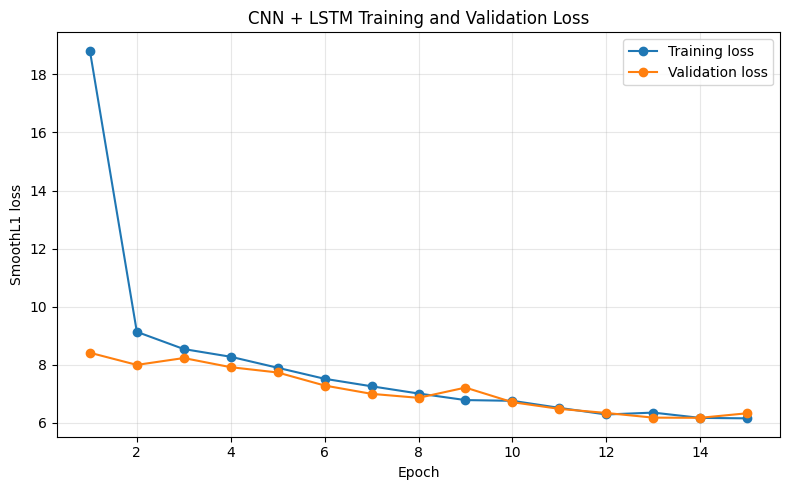

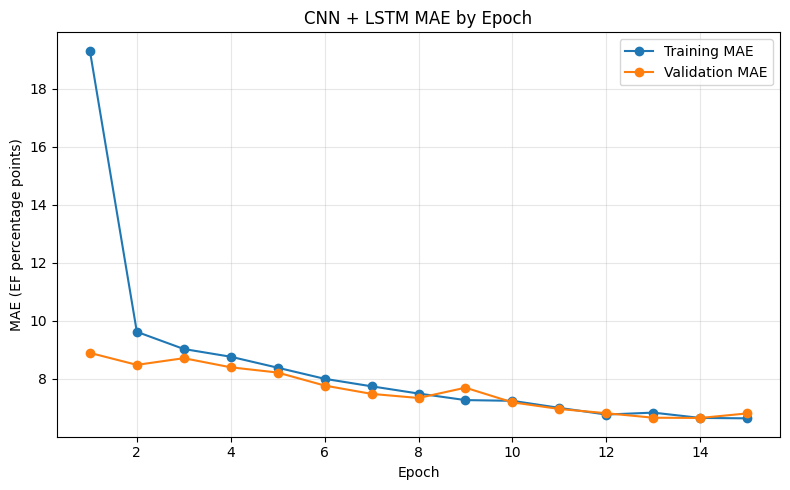

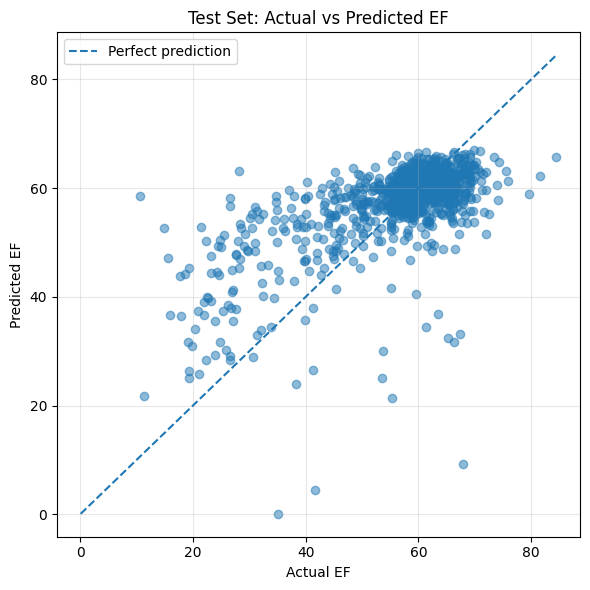

Saved plots:
/kaggle/working/EchoNet_CNN_LSTM_Results/training_loss.png
/kaggle/working/EchoNet_CNN_LSTM_Results/training_mae.png
/kaggle/working/EchoNet_CNN_LSTM_Results/test_actual_vs_predicted.png


In [39]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

history_df = pd.read_csv(HISTORY_PATH)

# 1. Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("SmoothL1 loss")
plt.title("CNN + LSTM Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    OUTPUT_DIR, "training_loss.png"
)
plt.savefig(loss_plot_path, dpi=200)
plt.show()

# 2. Training and validation MAE
plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_mae"],
    marker="o",
    label="Training MAE"
)
plt.plot(
    history_df["epoch"],
    history_df["val_mae"],
    marker="o",
    label="Validation MAE"
)
plt.xlabel("Epoch")
plt.ylabel("MAE (EF percentage points)")
plt.title("CNN + LSTM MAE by Epoch")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

mae_plot_path = os.path.join(
    OUTPUT_DIR, "training_mae.png"
)
plt.savefig(mae_plot_path, dpi=200)
plt.show()

# 3. Actual vs predicted EF on the test set
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.5)

min_val = min(float(y_true.min()), float(y_pred.min()))
max_val = max(float(y_true.max()), float(y_pred.max()))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual EF")
plt.ylabel("Predicted EF")
plt.title("Test Set: Actual vs Predicted EF")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

scatter_plot_path = os.path.join(
    OUTPUT_DIR, "test_actual_vs_predicted.png"
)
plt.savefig(scatter_plot_path, dpi=200)
plt.show()

print("Saved plots:")
print(loss_plot_path)
print(mae_plot_path)
print(scatter_plot_path)

In [40]:
import os

print("========== FINAL OUTPUT FILES ==========")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.isfile(path):
        print(f"{filename:40s} {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nResults folder:")
print(OUTPUT_DIR)

========== FINAL OUTPUT FILES ==========
best_cnn_lstm_model.pt                   6.55 MB
selected_frame_map.csv                   11.12 MB
sequence_manifest.csv                    0.69 MB
test_actual_vs_predicted.png             0.17 MB
test_metrics.csv                         0.00 MB
test_predictions.csv                     0.05 MB
training_history.csv                     0.00 MB
training_loss.png                        0.08 MB
training_mae.png                         0.08 MB

Results folder:
/kaggle/working/EchoNet_CNN_LSTM_Results
